# Tabular Data Challenge — Solubility Prediction

Predict the dependent variable **Y** (solubility) from 295 blinded molecular descriptors (X1–X339) using gradient boosting models.

Evaluation metric: **RMSE**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

from xgboost import XGBRegressor
from catboost import CatBoostRegressor

RANDOM_STATE = 42
DATA_DIR = '../data/challenge'

## 1. Load the data

In [2]:
train_df = pd.read_csv(f'{DATA_DIR}/TrainingData_Blinded.csv')
test_df  = pd.read_csv(f'{DATA_DIR}/TestData_Blinded_NoY.csv')

feature_cols = sorted([c for c in train_df.columns if c.startswith('X')])

X = train_df[feature_cols].values
y = train_df['Y'].values
X_test = test_df[feature_cols].values
test_names = test_df['Name'].values

print(f'Training set: {X.shape[0]} samples, {X.shape[1]} features')
print(f'Test set:     {X_test.shape[0]} samples')
print(f'Target range: [{y.min():.3f}, {y.max():.3f}], mean={y.mean():.3f}, std={y.std():.3f}')

Training set: 1087 samples, 295 features
Test set:     272 samples
Target range: [-0.713, 0.950], mean=0.005, std=0.315


## 2. Quick EDA

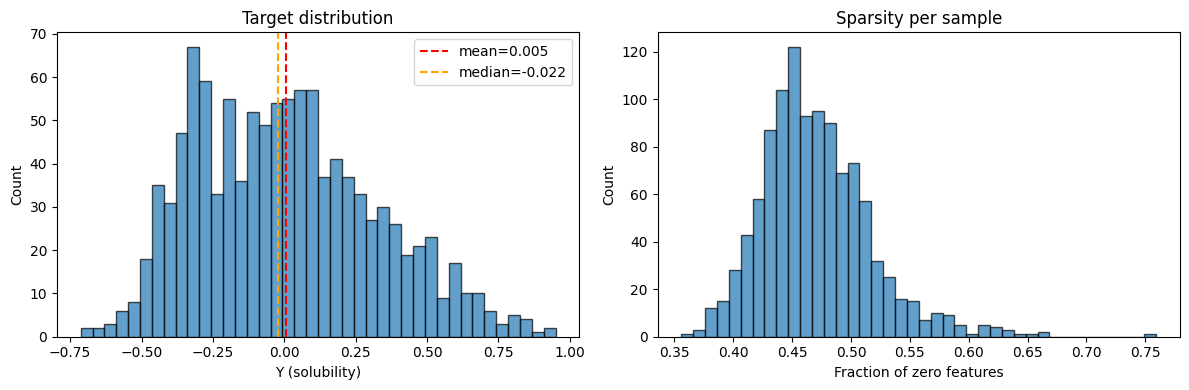

Columns with >90% zeros: 96
Columns with >50% zeros: 140


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(y, bins=40, edgecolor='black', alpha=0.7)
axes[0].axvline(y.mean(), color='red', linestyle='--', label=f'mean={y.mean():.3f}')
axes[0].axvline(np.median(y), color='orange', linestyle='--', label=f'median={np.median(y):.3f}')
axes[0].set_xlabel('Y (solubility)')
axes[0].set_ylabel('Count')
axes[0].set_title('Target distribution')
axes[0].legend()

# Fraction of zero-valued features per sample
zero_frac = (train_df[feature_cols] == 0).mean(axis=1)
axes[1].hist(zero_frac, bins=40, edgecolor='black', alpha=0.7)
axes[1].set_xlabel('Fraction of zero features')
axes[1].set_ylabel('Count')
axes[1].set_title('Sparsity per sample')

plt.tight_layout()
plt.show()

print(f'Columns with >90% zeros: {(train_df[feature_cols] == 0).mean().gt(0.9).sum()}')
print(f'Columns with >50% zeros: {(train_df[feature_cols] == 0).mean().gt(0.5).sum()}')

## 3. Train / validation split

In [4]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print(f'Train: {X_train.shape[0]},  Validation: {X_val.shape[0]}')

Train: 869,  Validation: 218


## 4. Baseline models with Pipeline

Both models use the same preprocessing: `VarianceThreshold` → `StandardScaler` → model.

In [5]:
def build_pipeline(model):
    return Pipeline([
        ('variance', VarianceThreshold(threshold=0.0)),
        ('scaler', StandardScaler()),
        ('model', model),
    ])

def evaluate(pipeline, X_tr, y_tr, X_v, y_v, name=''):
    pipeline.fit(X_tr, y_tr)
    y_pred = pipeline.predict(X_v)
    rmse = np.sqrt(mean_squared_error(y_v, y_pred))
    mae  = mean_absolute_error(y_v, y_pred)
    r2   = r2_score(y_v, y_pred)
    print(f'{name:25s}  RMSE={rmse:.4f}  MAE={mae:.4f}  R²={r2:.4f}')
    return rmse

In [6]:
xgb_baseline = build_pipeline(XGBRegressor(
    n_estimators=500, max_depth=5, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE
))

cat_baseline = build_pipeline(CatBoostRegressor(
    iterations=500, depth=6, learning_rate=0.05,
    random_seed=RANDOM_STATE, verbose=0
))

print('--- Baseline (validation set) ---')
evaluate(xgb_baseline, X_train, y_train, X_val, y_val, 'XGBoost baseline')
evaluate(cat_baseline, X_train, y_train, X_val, y_val, 'CatBoost baseline')

--- Baseline (validation set) ---


XGBoost baseline           RMSE=0.2196  MAE=0.1709  R²=0.5007


CatBoost baseline          RMSE=0.2145  MAE=0.1662  R²=0.5236


np.float64(0.21452562188826835)

## 5. Cross-validation comparison

In [7]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_rmse(model, name=''):
    pipe = build_pipeline(model)
    scores = cross_val_score(pipe, X, y, cv=cv, scoring='neg_root_mean_squared_error')
    rmses = -scores
    print(f'{name:25s}  CV-RMSE: {rmses.mean():.4f} ± {rmses.std():.4f}  (folds: {np.round(rmses, 4)})')
    return rmses.mean()

cv_rmse(XGBRegressor(n_estimators=500, max_depth=5, learning_rate=0.05,
                     subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE), 'XGBoost baseline')
cv_rmse(CatBoostRegressor(iterations=500, depth=6, learning_rate=0.05,
                          random_seed=RANDOM_STATE, verbose=0), 'CatBoost baseline')

XGBoost baseline           CV-RMSE: 0.2169 ± 0.0153  (folds: [0.2158 0.2123 0.1914 0.229  0.2358])


CatBoost baseline          CV-RMSE: 0.2166 ± 0.0138  (folds: [0.2154 0.217  0.1919 0.2272 0.2315])


np.float64(0.2165984047655362)

## 6. Hyperparameter tuning

Multiple configurations were tested for both XGBoost and CatBoost, varying tree depth, learning rate, number of estimators, subsampling, and regularization. The best CV-RMSE scores clustered around 0.213 for both models, with diminishing returns from further tuning. The best configuration found:

In [8]:
best_xgb = build_pipeline(XGBRegressor(
    n_estimators=2000, max_depth=7, learning_rate=0.005,
    subsample=0.7, colsample_bytree=0.4, random_state=RANDOM_STATE
))

best_cat = build_pipeline(CatBoostRegressor(
    iterations=2000, depth=6, learning_rate=0.01,
    l2_leaf_reg=1, random_seed=RANDOM_STATE, verbose=0
))

print('--- Tuned models (5-fold CV) ---')
cv_rmse(best_xgb.named_steps['model'], 'XGBoost (tuned)')
cv_rmse(best_cat.named_steps['model'], 'CatBoost (tuned)')

--- Tuned models (5-fold CV) ---


XGBoost (tuned)            CV-RMSE: 0.2128 ± 0.0138  (folds: [0.2115 0.2069 0.1908 0.2269 0.2281])


CatBoost (tuned)           CV-RMSE: 0.2135 ± 0.0130  (folds: [0.213  0.2125 0.1903 0.2249 0.2269])


np.float64(0.21352256028894773)

## 7. Select the best model and retrain on full data

In [9]:
# XGBoost achieved the best CV-RMSE — retrain on full training data
final_pipeline = best_xgb
final_pipeline.fit(X, y)
print('Best model: XGBoost (tuned)')

Best model: XGBoost (tuned)


## 8. Cross-validated diagnostics

In [10]:
from sklearn.model_selection import cross_val_predict

# Cross-validated predictions — each sample predicted when it was in the holdout fold
y_cv_pred = cross_val_predict(best_xgb, X, y, cv=cv)

cv_rmse_final = np.sqrt(mean_squared_error(y, y_cv_pred))
cv_r2_final = r2_score(y, y_cv_pred)
print(f'Cross-validated RMSE: {cv_rmse_final:.4f}')
print(f'Cross-validated R²:   {cv_r2_final:.4f}')

Cross-validated RMSE: 0.2133
Cross-validated R²:   0.5425


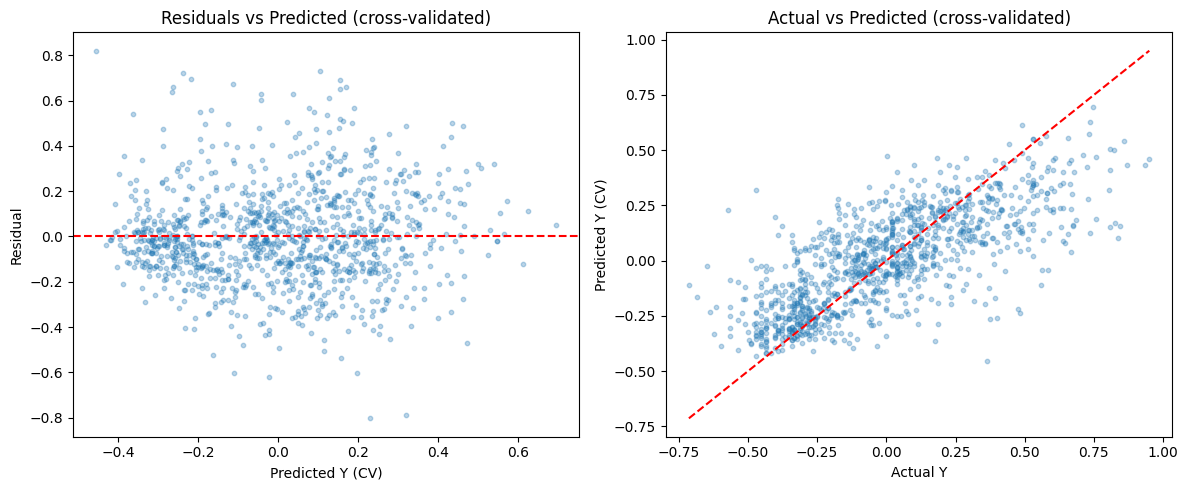

In [11]:
# Residual plot using cross-validated predictions
residuals = y - y_cv_pred
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_cv_pred, residuals, alpha=0.3, s=10)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Predicted Y (CV)')
axes[0].set_ylabel('Residual')
axes[0].set_title('Residuals vs Predicted (cross-validated)')

axes[1].scatter(y, y_cv_pred, alpha=0.3, s=10)
lims = [min(y.min(), y_cv_pred.min()), max(y.max(), y_cv_pred.max())]
axes[1].plot(lims, lims, 'r--')
axes[1].set_xlabel('Actual Y')
axes[1].set_ylabel('Predicted Y (CV)')
axes[1].set_title('Actual vs Predicted (cross-validated)')

plt.tight_layout()
plt.show()

## 10. Generate predictions for the test set

The `GridSearchCV` with `refit=True` (default) already fitted the best estimator on the full training data.

In [12]:
Y_pred = final_pipeline.predict(X_test)

submission = pd.DataFrame({'Name': test_names, 'Y_pred': Y_pred})
print(submission.head(10))
print(f'\nPrediction stats: mean={Y_pred.mean():.4f}, std={Y_pred.std():.4f}, '
      f'range=[{Y_pred.min():.4f}, {Y_pred.max():.4f}]')

  Name    Y_pred
0   T4 -0.027110
1  T15  0.433484
2  T24 -0.384711
3  T28  0.397122
4  T32  0.166138
5  T33  0.025113
6  T37  0.343658
7  T46 -0.168934
8  T65  0.200704
9  T68  0.038423

Prediction stats: mean=0.0753, std=0.2301, range=[-0.4232, 0.7667]


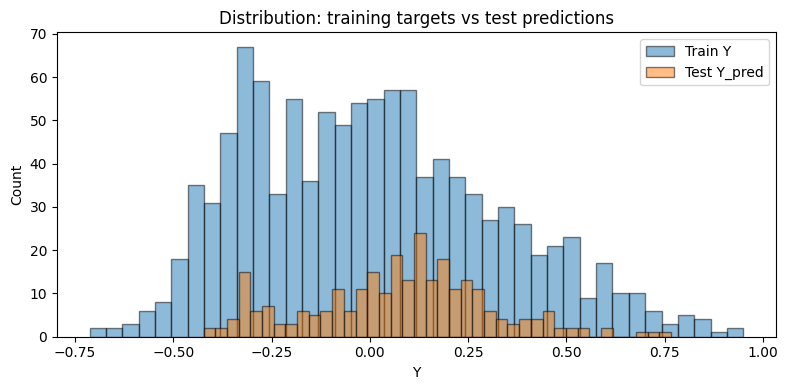

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(y, bins=40, alpha=0.5, label='Train Y', edgecolor='black')
ax.hist(Y_pred, bins=40, alpha=0.5, label='Test Y_pred', edgecolor='black')
ax.set_xlabel('Y')
ax.set_ylabel('Count')
ax.set_title('Distribution: training targets vs test predictions')
ax.legend()
plt.tight_layout()
plt.show()

In [14]:
submission.to_csv('challenge.csv', index=False)
print('Saved challenge.csv')
print(submission.shape)

Saved challenge.csv
(272, 2)
